In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Student_Performance_Dataset.csv')

In [5]:
df

,Student_ID,Age,Gender,Class,Study_Hours_Per_Day,Attendance_Percentage,Parental_Education,Internet_Access,Extracurricular_Activities,Math_Score,Science_Score,English_Score,Previous_Year_Score,Final_Percentage,Performance_Level,Pass_Fail
0,S0001,15,Male,12,1.0,65,Postgraduate,No,No,40,39,72,81,50.33,Average,Pass
1,S0002,19,Female,9,1.6,58,Graduate,No,Yes,80,44,35,47,53.00,Average,Pass
2,S0003,14,Female,12,3.6,64,High School,Yes,Yes,83,73,59,58,71.67,Good,Pass
3,S0004,18,Female,9,5.5,68,Postgraduate,Yes,No,68,48,77,54,64.33,Average,Pass
4,S0005,14,Male,10,5.0,80,High School,Yes,No,41,46,36,68,41.00,Poor,Fail
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,S4996,17,Male,11,4.0,50,Graduate,No,No,64,60,70,93,64.67,Average,Pass
4996,S4997,19,Male,10,5.6,90,High School,Yes,No,44,59,43,63,48.67,Poor,Fail
4997,S4998,16,Female,9,2.3,61,Graduate,No,No,95,41,82,62,72.67,Good,Pass
4998,S4999,15,Male,11,2.9,82,Graduate,No,Yes,66,45,61,75,57.33,Average,Pass


In [3]:
df.fillna(df.mean(numeric_only=True), inplace=True)

In [6]:

X = df[["Age", "Study_Hours_Per_Day", "Attendance_Percentage", "Final_Percentage"]]
y = df["Pass_Fail"]

In [7]:
encoder = LabelEncoder()
y = encoder.fit_transform(y)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4000
Testing samples: 1000


In [9]:
model = GaussianNB()
model.fit(X_train, y_train)

GaussianNB()

In [10]:
y_pred = model.predict(X_test)

In [11]:
print("\n--- Evaluation Metrics ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")


--- Evaluation Metrics ---
Accuracy:  0.9870
Precision: 0.9865
Recall:    1.0000
F1-score:  0.9932


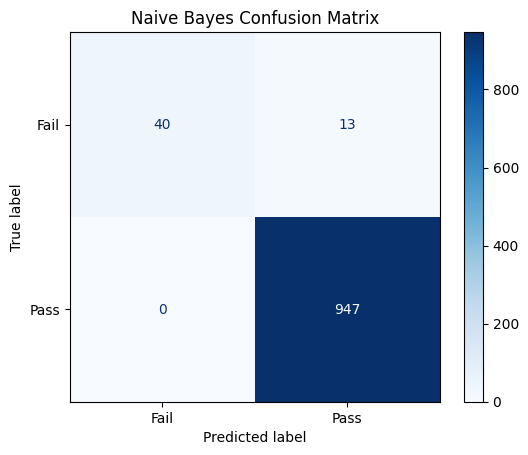

In [12]:
disp = ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=encoder.classes_,
    cmap="Blues"
)
plt.title("Naive Bayes Confusion Matrix")
plt.show()